In [2]:
#Import  libraries
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

#load the dataset
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

#Clean data
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])


c:\Users\jenin\anaconda3\envs\Python_Data_Project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_US = df[df["job_country"] == 'United States'].copy()

In [4]:
df_US["job_posted_month"] = df_US["job_posted_date"].dt.strftime("%B")

In [5]:
df_US.head(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,June
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',...",July
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"['python', 'sql', 'gcp']","{'cloud': ['gcp'], 'programming': ['python', '...",November
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","['sql', 'python', 'java', 'sql server', 'gcp',...","{'cloud': ['gcp', 'bigquery'], 'databases': ['...",March
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'...",April


In [6]:
df_US_pivot = df_US.pivot_table(index="job_posted_month", columns="job_title_short",aggfunc="size")

In [7]:
df_US_pivot.reset_index(inplace=True)

In [8]:
df_US_pivot.reset_index(inplace=True)
df_US_pivot["month_no"] = pd.to_datetime(df_US_pivot["job_posted_month"],format='%B').dt.month
df_US_pivot.sort_values("month_no", inplace=True)
df_US_pivot.set_index('job_posted_month', inplace=True)
df_US_pivot.drop(columns="month_no",inplace=True)
df_US_pivot

job_title_short,index,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,,
January,4,527,36,8494,2655,6915,60,1544,773,1552,114
February,3,447,24,6124,3060,4956,56,1258,878,1127,90
March,7,438,19,6218,3183,4779,59,1114,829,1150,115
April,0,565,40,6049,2801,4867,51,1025,781,991,112
May,8,279,20,4993,2976,4377,49,839,746,914,90
June,6,446,32,5683,2893,4645,48,1009,812,1033,93
July,5,581,39,5201,2570,4876,65,883,747,1095,153
August,1,903,39,6634,3269,6318,68,1186,903,1515,194
September,11,897,50,4639,3224,4568,113,805,775,1014,228


<Axes: xlabel='job_posted_month'>

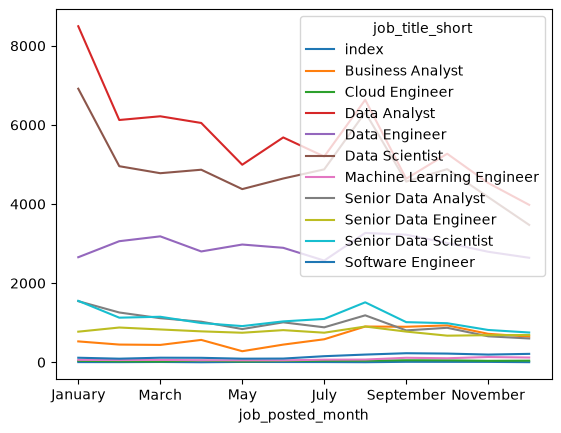

In [9]:
df_US_pivot.plot(kind='line')

In [10]:
top =df["job_title_short"].value_counts().head(3)
top = top.index.to_list()

<Axes: xlabel='job_posted_month'>

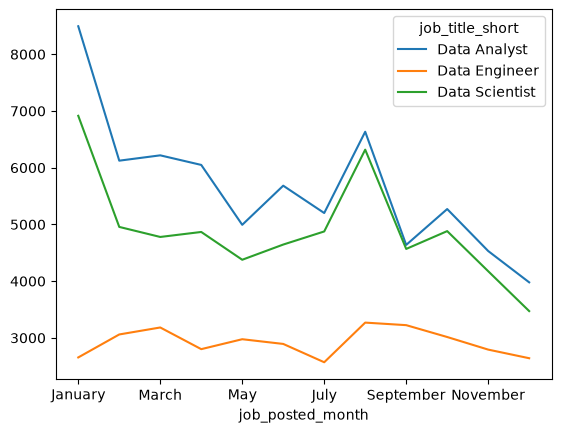

In [12]:
df_US_pivot[top].plot(kind="line")


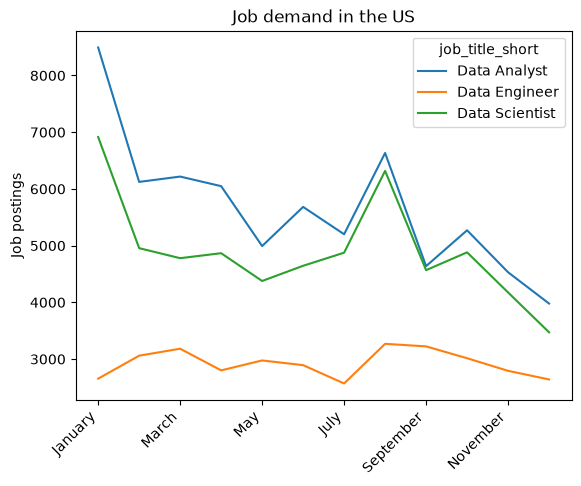

In [ ]:
df_US_pivot[top].plot(kind="line")
plt.ylabel('Job postings')
plt.xlabel('')
plt.title('Job demand in the US')
plt.xticks(rotation=45,ha = "right")


plt.show()
